# CS207 - Data functions

Imports

In [1300]:
import sys
import numpy

import matplotlib.pyplot as plt
colors_ham_spam = ["#ff7dfb", "#ffcf69"]

import sklearn
import random
import statistics

import csv
import string

#### Seed

In [1301]:
random_seed = random.seed(10)

### Opening CSV as "data"

In [1302]:
with open("spam.csv", "r", encoding="cp1252") as file:
  reader = csv.reader(file)
  data = list(reader)

## **Data clean up**

Identifying data in each row

In [1303]:
print("Column count:", len(data[0]))
print("Headers:", data[0])

# Find rows with extra data and try to understand it
print("Rows with extra data:")
found = 0
for i, row in enumerate(data[1:], start=1):
  if any(row[2:]):
    print(f"Row {i}: {row}")
    found += 1
    
    if found == 10:
      break

# Try joining row 96 to see if it makes sense
row = data[96]
print(row[1:])
print(",".join(row[1:]))

Column count: 5
Headers: ['v1', 'v2', '', '', '']
Rows with extra data:
Row 96: ['spam', 'Your free ringtone is waiting to be collected. Simply text the password \\MIX\\" to 85069 to verify. Get Usher and Britney. FML', ' PO Box 5249', ' MK17 92H. 450Ppw 16"', '']
Row 282: ['ham', '\\Wen u miss someone', ' the person is definitely special for u..... But if the person is so special', ' why to miss them', ' just Keep-in-touch\\" gdeve.."']
Row 445: ['ham', '\\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAROUND! HOWDY GORGEOUS', ' HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE JEN XXX\\""', '', '']
Row 672: ['spam', 'SMS. ac sun0819 posts HELLO:\\You seem cool', ' wanted to say hi. HI!!!\\" Stop? Send STOP to 62468"', '', '']
Row 711: ['ham', 'Height of Confidence: All the Aeronautics professors wer calld &amp; they wer askd 2 sit in an aeroplane. Aftr they sat they wer told dat the plane ws made by their students. Dey all hurried out of d plane.. Bt only 1 didnt move... He said:\\if it is ma

---

#### **I love CS207, but it does not love me back, TAT**

| 0 | 1 | 2 | 3 |
|---|---|---|---|
|ham|"I love CS207 | but it does not love me back | TAT |

CSV columns are separated by ","
some commas are part of a message, but separated any way.

We will clean it up by joining the second column onwards.
The data will become only:

| 0 | 1 |
|---|---|
|ham|"I love CS207, but it does not love me back, TAT" |


In [1304]:
joined_data = [["v1", "v2"]]

for row in data[1:]:
  message_parts = row[1:]
  
  # Remove column with empty value before joining
  while message_parts and message_parts[-1] == "":
    message_parts.pop()
  
  row_data = []
  row_data.append(row[0])
  row_data.append(",".join(message_parts))
  
  joined_data.append(row_data)

### Sanity check ###

# Total rows and column
print("Total rows:", len(joined_data))
print("Columns per row:", len(joined_data[1]))

empty_labels = 0			# labels : ham / spam
empty_messages = 0

for row in joined_data[1:]:
  if row[0] == "":
    empty_labels += 1
    
  if row[1] == "":
    empty_messages += 1
    
print("Empty labels:", empty_labels)
print("Empty messages:", empty_messages)

# Label check (Make sure that there's only "ham" and "spam")
labels = set()

for row in joined_data[1:]:
    labels.add(row[0])

print(labels)

Total rows: 5573
Columns per row: 2
Empty labels: 0
Empty messages: 0
{'spam', 'ham'}


No empty labels and messages after joining. 🎉

---
### **Separating data (ham and spam)**

In [1305]:
headers = [joined_data[0]]
ham = []
spam = []

for row in joined_data[1:]:
  if row[0] == "ham":
    ham.append(row)
  elif row[0] == "spam":
    spam.append(row)

Distribution visualization

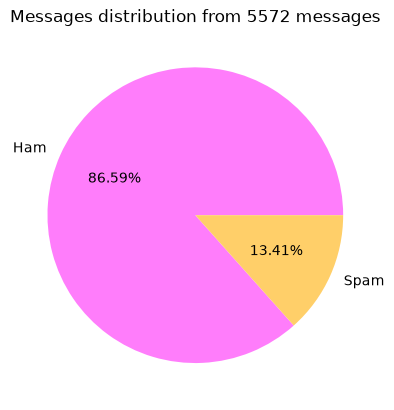

In [1306]:
labels = ["Ham", "Spam"]
counts = [len(ham), len(spam)]
all_messages = sum(counts)

plt.title(f"Messages distribution from {all_messages} messages")
plt.pie(
  counts,
  labels=labels,
  colors=colors_ham_spam,
  autopct="%1.2f%%")
plt.show()

---

### **Identifying features of the messages**

##### **Average words**

In [1307]:
ham_word_counts = []
spam_word_counts = []

for row in ham:
  message = row[1]
  words = message.split()
  ham_word_counts.append(len(words))
  
for row in spam:
  message = row[1]
  words = message.split()
  spam_word_counts.append(len(words))
  
ham_average_word_count = sum(ham_word_counts) / len(ham)
spam_average_word_count = sum(spam_word_counts) / len(spam)

#### Bar chart

<BarContainer object of 2 artists>

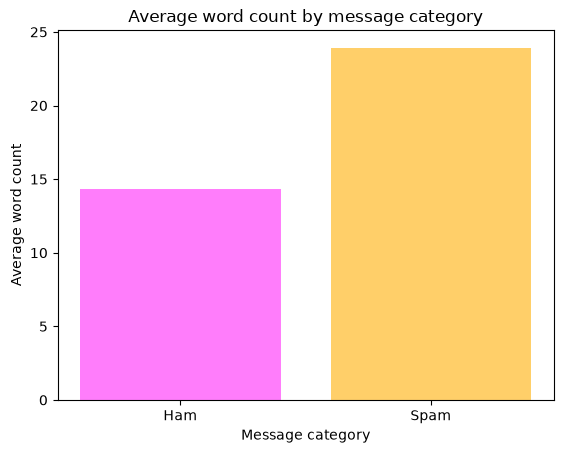

In [1308]:
labels = ["Ham", "Spam"]
averages = [ham_average_word_count, spam_average_word_count]

plt.title("Average word count by message category")
plt.xlabel("Message category")
plt.ylabel("Average word count")

plt.bar(labels, averages, color=colors_ham_spam)

#### Histogram

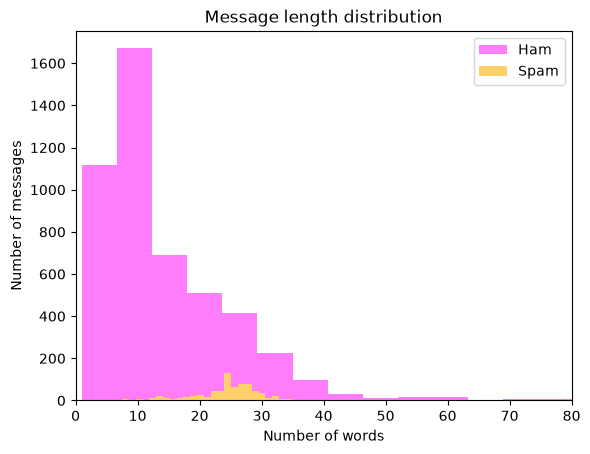

In [1309]:
plt.title("Message length distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of messages")

plt.hist(
    ham_word_counts,
    bins=30,
    color=colors_ham_spam[0],
    label="Ham"
)

plt.hist(
    spam_word_counts,
    bins=30,
    color=colors_ham_spam[1],
    label="Spam"
)

# Limit the x axis of the visualization
# Messages length are concentrated around 0-50 words
plt.xlim(0, 80)
plt.xticks(range(0, 81, 10))

plt.legend()
plt.show()

> Ham: Most ham messages contain around 10-16 words per message.
>
> Spam: Messages tends to be longer, it has a higher average word count around low-to-mid 20s.

#### **The big 3 - Mean, Median, Mode**

#### Mean

In [1310]:
ham_mean = ham_average_word_count
spam_mean = spam_average_word_count

print("Ham mean:", round(ham_mean, 2))
print("Spam mean:", round(spam_mean, 2))

Ham mean: 14.31
Spam mean: 23.91


##### Median

In [1311]:
ham_sorted = sorted(ham_word_counts)
spam_sorted = sorted(spam_word_counts)

ham_middle = len(ham_sorted) // 2
spam_middle = len(spam_sorted) // 2

ham_median = (
	ham_sorted[ham_middle - 1] + ham_sorted[ham_middle]
) / 2

spam_median = (
	spam_sorted[spam_middle - 1] + spam_sorted[spam_middle]
) / 2

print("Ham median:", ham_median)
print("Spam median:", spam_median)

Ham median: 11.0
Spam median: 25.0


##### Mode

In [1312]:
ham_word_frequencies = {}

# Go through all numbers of word counts, add to a dict.
for word_count in ham_word_counts:
  if word_count not in ham_word_frequencies:
    ham_word_frequencies[word_count] = 1
  else:
    ham_word_frequencies[word_count] += 1

# Find mode by sorting and then pick the first value
sorted_ham_frequencies = sorted(
  ham_word_frequencies.items(),
  key=lambda item: item[1],
  reverse=True
)

ham_mode = sorted_ham_frequencies[0][0]

In [1313]:
spam_word_frequencies = {}

for word_count in spam_word_counts:
    if word_count not in spam_word_frequencies:
        spam_word_frequencies[word_count] = 1
    else:
        spam_word_frequencies[word_count] += 1

sorted_spam_frequencies = sorted(
    spam_word_frequencies.items(),
    key=lambda item: item[1],
    reverse=True
)

spam_mode = sorted_spam_frequencies[0][0]


In [1314]:
print("Ham mode:", ham_mode)
print("Spam mode:", spam_mode)

Ham mode: 6
Spam mode: 27


### Measures of central tendency

| Statistic | Ham | Spam |
|---|---|---|
| Mean | 14.31 | 23.91 |
| Median | 11.00 | 25.00 |
| Mode | 6 | 27 |

---

## **Standard deviation**

In [1315]:
ham_squared_differences = []

for word_count in ham_word_counts:
  difference = word_count - ham_mean
  squared_differences = difference ** 2
  ham_squared_differences.append(squared_differences)

In [1316]:
spam_squared_differences = []

for word_count in spam_word_counts:
  difference = word_count - spam_mean
  squared_differences = difference ** 2
  spam_squared_differences.append(squared_differences)

### **Variance**

In [1317]:
ham_variance = sum(ham_squared_differences) / len(ham_squared_differences)
spam_variance = sum(spam_squared_differences) / len(spam_squared_differences)

print("Ham variance:", ham_variance)
print("Spam variance:", spam_variance)

Ham variance: 132.41572552283282
Spam variance: 33.36568765019919


### **Standard deviation**

In [1318]:
ham_standard_deviation = ham_variance ** 0.5
spam_standard_deviation = spam_variance ** 0.5

print("Ham SD:", ham_standard_deviation)
print("Spam SD:", spam_standard_deviation)


Ham SD: 11.507203201596504
Spam SD: 5.776303978341097


| Statistic | Ham | Spam |
|---|---|---|
| Variance | 132.42 | 33.37 |
| Standard deviation | 11.51 | 5.78 |

---

## **Bayes's Theorem**  

### **P (A | B)**
We know `B`, now we find out what `A` is.

Probabilities

In [1319]:
total_messages = len(ham) + len(spam)

ham_probability = len(ham) / total_messages
spam_probability = len(spam) / total_messages

print("Probability of ham:", ham_probability)
print("Probability of spam:", spam_probability)

Probability of ham: 0.8659368269921034
Probability of spam: 0.13406317300789664


Count all the words in all messages.  
To find out how many words are present in each message in each category.

Stop words: Common words that has little meaning, serves as articles, prepositions, etc.

In [1320]:
stop_words = {
    "a", "an", "the", "this", "that",
    "to", "and", "in", "is", "am", "are",
    "i", "you", "u", "my", "im", "me", "of",
    "for", "it", "have", "but", "your", "so",
    "on", "at", "if", "do",
    "be", "we", "with", "ill",
    "when", "how", "up", "ur", "what",
    "got", ".", "or", "was",
    "its", "then", "?", "he", "out",
    "ltgt"
}

In [1321]:
translator = str.maketrans("", "", string.punctuation)

ham_word_frequencies = {}
spam_word_frequencies = {}

# Go through all messages, add words to the dictionary
# Skip numbers
for row in ham:
  message = row[1].lower().split()
  
  for word in message:
    # Remove punctuation from words
    word = word.translate(translator)
    
    if not word or word.isdigit() or word in stop_words:
      continue
      
    ham_word_frequencies[word] = (
      ham_word_frequencies.get(word, 0) + 1
    )

for row in spam:
  message = row[1].lower().split()

  for word in message:
    word = word.translate(translator)
    
    if not word or word.isdigit() or word in stop_words:
      continue
    
    spam_word_frequencies[word] = (
      spam_word_frequencies.get(word, 0) + 1
    )

Sort the most frequent words

In [1322]:
sorted_ham_words = sorted(
  ham_word_frequencies.items(), 
  key=lambda item: item[1], 
  reverse=True
)
sorted_spam_words = sorted(
  spam_word_frequencies.items(), 
  key=lambda item: item[1], 
  reverse=True
)

In [1323]:
print("Top 20 Ham Words:")
for word, count in sorted_ham_words[:20]:
    print(f"{word}: {count}")

print("\nTop 20 Spam Words:")
for word, count in sorted_spam_words[:20]:
    print(f"{word}: {count}")

Top 20 Ham Words:
not: 412
can: 376
will: 339
get: 303
just: 290
now: 289
no: 274
ok: 273
dont: 265
go: 250
all: 241
know: 232
like: 231
call: 231
come: 227
good: 224
love: 190
time: 189
day: 188
there: 185

Top 20 Spam Words:
call: 347
free: 216
now: 189
txt: 150
from: 128
mobile: 123
text: 120
stop: 115
claim: 113
reply: 101
prize: 92
our: 85
get: 83
only: 79
just: 78
won: 73
new: 69
send: 68
nokia: 65
urgent: 63


A function for getting the frequency of words and its difference

In [1324]:
def compare_word_frequency(word):
  ham_count = ham_word_frequencies.get(word, 0)
  spam_count = spam_word_frequencies.get(word, 0)
  difference = ham_count - spam_count
  
  return ham_count, spam_count, difference

### **Word to compare**

In [1325]:
word_to_compare = "call"

In [1326]:
compared_word = compare_word_frequency(word_to_compare.lower())

compared_word_ham = compared_word[0]
compared_word_spam = compared_word[1]
difference = abs(compared_word[2])

print("Comparing:", {word_to_compare})
print("Ham:", compared_word_ham, "words.")
print("Spam:", compared_word_spam, "words.")
if compared_word[2] > 0:
  print("Ham has", difference, "more occurances.")
elif compared_word[2] < 0:
  print("Spam has", difference, "more occurances.")
else:
  print("Both have the same number of occurances.")

Comparing: {'call'}
Ham: 231 words.
Spam: 347 words.
Spam has 116 more occurances.


#### **Bayes theorem in action**

In [1327]:
def show_percentage_and_count(percentage):
  count = int(round(percentage * all_messages / 100))
  return f"{percentage:.2f}%\n({count})"

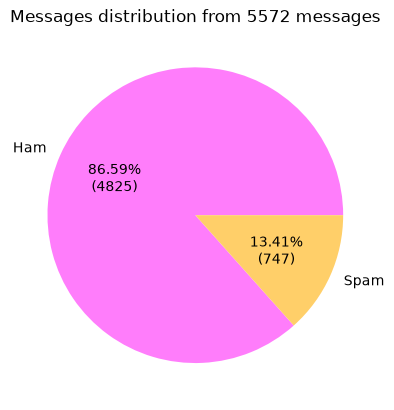

In [1328]:
# Copied from above

labels = ["Ham", "Spam"]
counts = [len(ham), len(spam)]
all_messages = sum(counts)

plt.title(f"Messages distribution from {all_messages} messages")
plt.pie(
  counts,
  labels=labels,
  colors=colors_ham_spam,
  autopct=show_percentage_and_count)
plt.show()

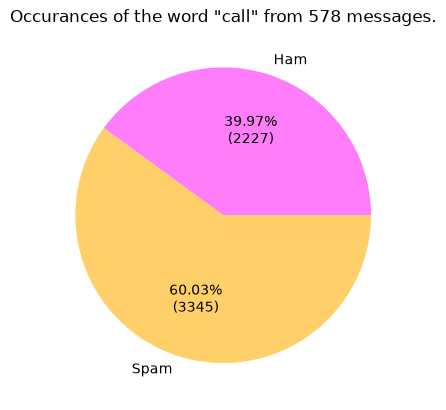

In [1329]:
labels = ["Ham", "Spam"]
counts = [compared_word_ham, compared_word_spam]
all_messages_containing_word = compared_word_ham + compared_word_spam

plt.title(f'Occurances of the word "{word_to_compare}" from {all_messages_containing_word} messages.')
plt.pie(
  counts,
  labels=labels,
  colors=colors_ham_spam,
  autopct=show_percentage_and_count
)
plt.show()

The probability that a message is spam, given that it contains the word `call`.  

In [1330]:
total_compared_word = compared_word_ham + compared_word_spam
spam_given_word = compared_word_spam / total_compared_word

print(f"P(spam | {word_to_compare}): {spam_given_word:.2%}")

P(spam | call): 60.03%


The probability that a message contains `call`, given that it is spam.

In [1331]:
word_given_spam = compared_word_spam / len(spam)

print(f"P({word_to_compare} | spam): {word_given_spam:.2%}")

P(call | spam): 46.45%


##### Out of all messages that contain the word `call`, `60.03% are spam`.  
##### Out of all spam messages, `46.45% contains the word call`.

What if we randomly pick a message, what's the probability that it's a spam message?

In [1332]:
print(f"P(spam): {spam_probability:.2%}")

P(spam): 13.41%


Out of all messages, how much of it contains the word `free`.

In [1333]:
word_probability = total_compared_word / all_messages

print(f"P({word_to_compare}): {word_probability:.2%}")

P(call): 10.37%


Let's apply Bayes' theorem

**P(spam | call) = ( P(call | spam) * P(spam) ) / P(call)**

In [1334]:
spam_given_word_bayes = (
	word_given_spam * spam_probability
) / word_probability

print(f"P(spam | {word_to_compare}): {spam_given_word_bayes:.2%}")

P(spam | call): 60.03%


#### **Our findings**

| Probability | Meaning | Result |
|-------------|---------|--------|
| P(call) | A random message containing `call` | 10.37% |
|	P(call \| spam) | A spam message containing `call` | 46.45% |
| P(spam) |	A random message is spam | 13.41% |
| P(spam \| call) | A spam message, given that it contains `call` | 60.03% |